# Chapter 5 · Physics-informed neural networks (PINNs): 1D and 2D twins
**Level: Expert** · ~60 min (training takes about 13 + 5 min on a laptop CPU) · 1D and 2D

Every twin so far had a **solver on a grid** at its heart. A PINN takes a different route: the
field itself is a neural network $u_\theta(x,t)$, a smooth function you can evaluate anywhere.
It is trained so that it **satisfies the PDE and matches the sensors at the same time**. Unknown
physical constants simply become extra trainable numbers, so the same training does
reconstruction **and** calibration.

| Part | Problem | What the PINN does |
|---|---|---|
| **0** | a one-line ODE | learn the idea in seconds |
| **A** | 1D Burgers equation (a near-shock) | forward solve, diagnostics, find the viscosity from 10 sensors |
| **B** | 2D puff in a flowing channel | reconstruct the field, identify κ and the velocity, forecast, find the release point |

**Prerequisites:** Chapters 1–3, and basic PyTorch (tensors, `.backward()`).

## Glossary
| Term | Meaning |
|---|---|
| **MLP** | multi-layer perceptron: layers of `linear → tanh`, a flexible smooth function |
| **automatic differentiation (autograd)** | exact derivatives of the network output with respect to its inputs, computed by the chain rule |
| **collocation points** | random points $(x,t)$ where we *ask* the network to satisfy the PDE |
| **residual** $\mathcal R$ | how badly the PDE is violated at a point: $u_t - (\dots)$ |
| **Adam / L-BFGS** | two optimisers: Adam is robust early on; L-BFGS polishes at the end |
| **spectral bias** | networks learn smooth features first and sharp ones last |

The loss function is a weighted sum of "how wrong" each piece is:

$$\mathcal L(\theta) = \underbrace{\tfrac{1}{N_r}\textstyle\sum |\mathcal R[u_\theta](x_i,t_i)|^2}_{\text{physics}} + w_0\underbrace{\tfrac{1}{N_0}\textstyle\sum|u_\theta(x,0)-u_0|^2}_{\text{initial condition}} + w_b\underbrace{\tfrac{1}{N_b}\textstyle\sum|u_\theta(\text{boundary})|^2}_{\text{boundaries}} + w_d\underbrace{\tfrac{1}{N_d}\textstyle\sum|u_\theta(x_j,t_j)-y_j|^2}_{\text{sensors}}$$

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from scipy.interpolate import griddata
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import burgers_exact
from dtwin.pinn import MLP, grad, tensor, train, set_seed
viz.set_style()
set_seed(0)
rng = np.random.default_rng(0)
torch.set_num_threads(max(1, torch.get_num_threads()))

---
# Part 0 · The PINN idea in one minute

## 0.1 Autograd: derivatives of a network, exactly
The PDE residual needs $u_t$, $u_x$, $u_{xx}$ of the *network*. PyTorch's autograd computes them
exactly by applying the chain rule through every layer. Sanity check on $y = x^3$:

In [2]:
xa = torch.linspace(-1, 1, 5, requires_grad=True)
ya = xa**3
dy = grad(ya, xa)          # dtwin.pinn.grad = torch.autograd.grad with create_graph=True
d2y = grad(dy, xa)         # ...so we can differentiate again
print("x       :", xa.detach().numpy())
print("dy/dx   :", dy.detach().numpy(), "  (exact 3x^2)")
print("d2y/dx2 :", d2y.detach().numpy(), "  (exact 6x)")

x       : [-1.  -0.5  0.   0.5  1. ]
dy/dx   : [3.   0.75 0.   0.75 3.  ]   (exact 3x^2)
d2y/dx2 : [-6. -3.  0.  3.  6.]   (exact 6x)


## 0.2 A tiny inverse PINN: decay rate from 8 noisy points
Take a cooling cup of coffee: $u' = -k\,u$, $u(0) = 1$, with $k$ **unknown**. We have 8 noisy
temperature readings. The network $u_\theta(t)$ and the number $k$ are trained **together** on
three losses:
* **physics:** $u_\theta' + k\,u_\theta = 0$ at 100 collocation times
* **initial condition:** $u_\theta(0) = 1$
* **data:** $u_\theta(t_j) \approx y_j$

adam     0  loss 2.708e+00  pde 1.38e-02  data 1.90e-01  (0s)


adam   500  loss 3.216e-03  pde 7.28e-04  data 2.22e-04  (0s)


adam  1000  loss 2.396e-03  pde 2.34e-04  data 2.01e-04  (1s)


adam  1500  loss 2.308e-03  pde 1.88e-04  data 1.99e-04  (1s)


adam  2000  loss 2.265e-03  pde 1.54e-04  data 1.99e-04  (1s)


adam  2499  loss 2.240e-03  pde 1.32e-04  data 1.99e-04  (1s)
k estimated 1.571   true 1.5


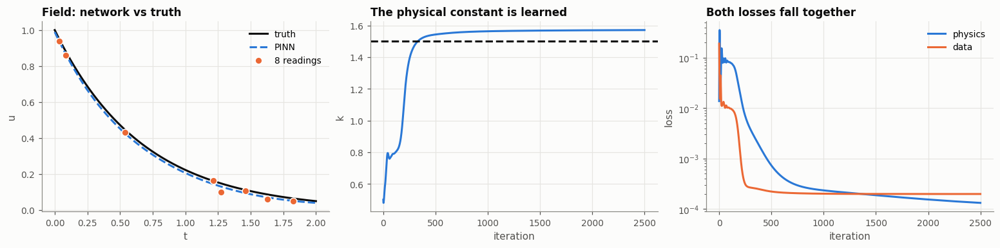

In [3]:
k_true = 1.5
t_d = np.sort(rng.uniform(0, 2, 8)); y_d = np.exp(-k_true * t_d) + rng.normal(0, 0.02, 8)
net0 = MLP(1, 1, width=24, depth=2, lb=[0.0], ub=[2.0])
log_k = torch.tensor(np.log(0.5), dtype=torch.float32, requires_grad=True)   # start 3x too small
tc = tensor(np.linspace(0, 2, 100)[:, None], requires_grad=True)
td, yd, t0_ = tensor(t_d[:, None]), tensor(y_d[:, None]), torch.zeros(1, 1)
k_hist = []

def loss0():
    u = net0(tc)
    res = grad(u, tc) + torch.exp(log_k) * u                # physics residual
    l_pde, l_ic = (res**2).mean(), ((net0(t0_) - 1) ** 2).mean()
    l_data = ((net0(td) - yd) ** 2).mean()
    k_hist.append(float(torch.exp(log_k)))
    return l_pde + l_ic + 10 * l_data, {"pde": l_pde.item(), "data": l_data.item()}

h0 = train(loss0, [{"params": list(net0.parameters())}, {"params": [log_k], "lr": 2e-2}],
           n_adam=2500, lr=5e-3, log_every=500)
print(f"k estimated {np.exp(log_k.item()):.3f}   true {k_true}")

tt = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), constrained_layout=True)
axes[0].plot(tt, np.exp(-k_true * tt), color=viz.TRUTH, label="truth")
axes[0].plot(tt, net0(tensor(tt[:, None])).detach().numpy(), color=viz.TWIN, ls="--", label="PINN")
axes[0].plot(t_d, y_d, "o", color=viz.DATA, ms=7, mec="white", label="8 readings")
axes[0].set(xlabel="t", ylabel="u", title="Field: network vs truth")
axes[0].legend()
axes[1].plot(k_hist, color=viz.TWIN); axes[1].axhline(k_true, color=viz.TRUTH, ls="--")
axes[1].set(xlabel="iteration", ylabel="k", title="The physical constant is learned")
axes[2].semilogy(h0["pde"], color=viz.BLUE, label="physics"); axes[2].semilogy(h0["data"], color=viz.ORANGE, label="data")
axes[2].set(xlabel="iteration", ylabel="loss", title="Both losses fall together")
axes[2].legend()
plt.show()

✅ **Check:** $k$ climbs from 0.5 to about 1.5. That's the whole PINN recipe. The rest of the
chapter applies it to real PDEs, where it gets harder: shocks, many parameters, unknown
initial conditions.

**Why is $k$ stored as $\log k$?** It keeps $k$ positive and makes the step size relative. It's
standard practice for physical constants that span orders of magnitude.

---
# Part A · 1D Burgers: forward and inverse PINN

$$u_t + u\,u_x = \nu\,u_{xx},\quad x\in[-1,1],\ t\in[0,1],\quad u(x,0)=-\sin(\pi x),\ u(\pm1,t)=0,\ \nu=0.01/\pi.$$

Burgers is a 1D model of nonlinear transport: the $u\,u_x$ term steepens the wave into a near-shock at $x=0$.

In [4]:
set_seed(0)                       # same random draws as a fresh run of Part A
rng = np.random.default_rng(0)
NU = 0.01 / np.pi

## A1. Ground truth via the Cole-Hopf transform
Burgers' equation linearises into the heat equation under $u=-2\nu\,\partial_x\log\phi$, which
gives an exact integral solution. We evaluate it by quadrature (`dtwin.solvers.burgers_exact`).

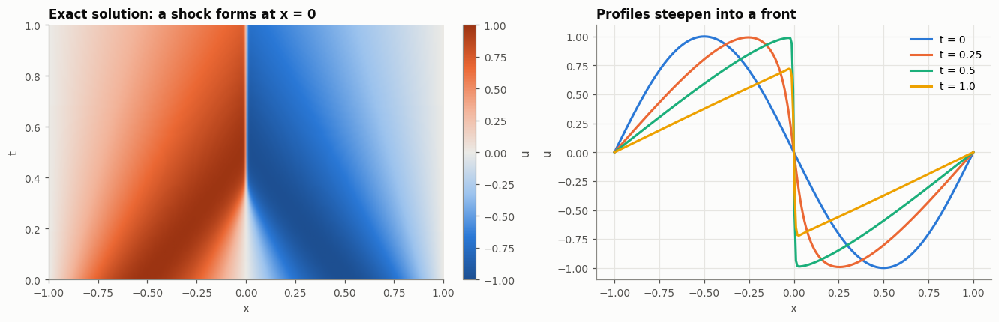

In [5]:
xg, tg = np.linspace(-1, 1, 256), np.linspace(0, 1, 101)
U_exact = burgers_exact(xg, tg, NU)
XX, TT = np.meshgrid(xg, tg)
grid_pts = tensor(np.c_[XX.ravel(), TT.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
viz.spacetime(axes[0], U_exact, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, label="u")
axes[0].set_title("Exact solution: a shock forms at x = 0")
for i, tk in enumerate([0, 0.25, 0.5, 1.0]):
    axes[1].plot(xg, U_exact[np.argmin(abs(tg - tk))], color=viz.SERIES[i], label=f"t = {tk}")
axes[1].set(xlabel="x", ylabel="u", title="Profiles steepen into a front")
axes[1].legend()
plt.show()

## A2. Forward PINN
* **Network:** 5 hidden layers × 40 tanh units; inputs rescaled to $[-1,1]$ inside the model.
* **Collocation points:** 8,000 random $(x,t)$ points where the residual is enforced.
* **Optimiser:** Adam to get into the right basin, then L-BFGS to polish (standard practice).

In [6]:
def residual(net, X, nu):
    u = net(X)
    du = grad(u, X)
    ux, ut = du[:, :1], du[:, 1:]
    uxx = grad(ux, X)[:, :1]
    return ut + u * ux - nu * uxx

Xc = tensor(np.c_[rng.uniform(-1, 1, 8000), rng.uniform(0, 1, 8000)], requires_grad=True)
x0 = rng.uniform(-1, 1, 256)
X0, U0 = tensor(np.c_[x0, np.zeros_like(x0)]), tensor(-np.sin(np.pi * x0)[:, None])
tb = rng.uniform(0, 1, 200)
Xb = tensor(np.c_[np.r_[-np.ones(100), np.ones(100)], tb])

net = MLP(2, 1, width=40, depth=5, lb=[-1, 0], ub=[1, 1])
snapshots = {}

def forward_loss():
    lr = (residual(net, Xc, NU) ** 2).mean()
    l0 = ((net(X0) - U0) ** 2).mean()
    lb = (net(Xb) ** 2).mean()
    return lr + 10 * l0 + 10 * lb, {"pde": lr.item(), "ic": l0.item(), "bc": lb.item()}

def snap(hist):
    it = len(hist["total"])
    if it in (100, 1000, 3000):
        with torch.no_grad():
            snapshots[it] = net(grid_pts).numpy().reshape(TT.shape)

t0 = time.time()
hist = train(forward_loss, list(net.parameters()), n_adam=3000, lr=2e-3, n_lbfgs=1500,
             log_every=1000, callback=snap)
with torch.no_grad():
    U_pinn = net(grid_pts).numpy().reshape(TT.shape)
snapshots["final"] = U_pinn
rel = np.linalg.norm(U_pinn - U_exact) / np.linalg.norm(U_exact)
print(f"relative L2 error {rel:.2e}   ({time.time() - t0:.0f}s)")

adam     0  loss 4.610e+00  pde 3.41e-04  ic 4.58e-01  bc 2.90e-03  (0s)


adam  1000  loss 1.958e-01  pde 1.63e-01  ic 3.15e-03  bc 1.01e-04  (22s)


adam  2000  loss 1.237e-01  pde 1.03e-01  ic 1.99e-03  bc 3.29e-05  (44s)


adam  2999  loss 2.005e-02  pde 1.63e-02  ic 3.61e-04  bc 1.02e-05  (66s)


lbfgs done  loss 6.295e-05  (103s)
relative L2 error 7.32e-03   (103s)


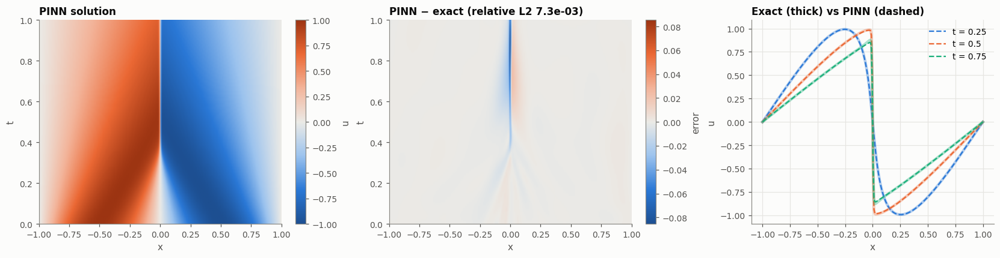

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
viz.spacetime(axes[0], U_pinn, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, label="u")
axes[0].set_title("PINN solution")
err = U_pinn - U_exact
lim = np.abs(err).max()
viz.spacetime(axes[1], err, xg, tg, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, label="error")
axes[1].set_title(f"PINN − exact (relative L2 {rel:.1e})")
for i, tk in enumerate([0.25, 0.5, 0.75]):
    k = np.argmin(abs(tg - tk))
    axes[2].plot(xg, U_exact[k], color=viz.SERIES[i], lw=3, alpha=0.35)
    axes[2].plot(xg, U_pinn[k], "--", color=viz.SERIES[i], lw=1.5, label=f"t = {tk}")
axes[2].set(xlabel="x", ylabel="u", title="Exact (thick) vs PINN (dashed)")
axes[2].legend()
viz.save(fig, "08_pinn_burgers.png")
plt.show()

## A3. Diagnosing a PINN
Three diagnostics every practitioner should look at:
1. **Loss components** separately: a low total can hide one term that never converged.
2. **How the solution forms during training:** PINNs learn smooth, low-frequency parts first
   (*spectral bias*) and the sharp front last.
3. **The residual map:** where the physics is still violated. Here, at the shock.

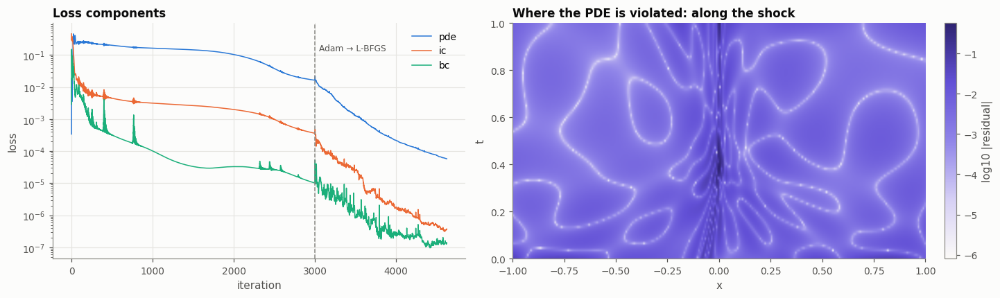

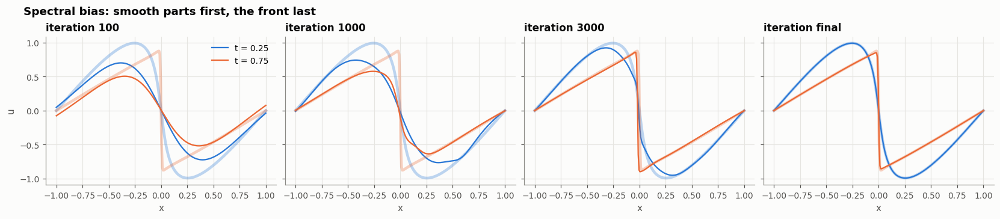

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
it = np.arange(len(hist["total"]))
for i, k in enumerate(["pde", "ic", "bc"]):
    axes[0].semilogy(it, hist[k], color=viz.SERIES[i], lw=1, label=k)
axes[0].axvline(3000, color=viz.MUTED, ls="--", lw=1)
axes[0].text(3050, max(hist["ic"]) * 0.3, "Adam → L-BFGS", color=viz.INK2, fontsize=8)
axes[0].set(xlabel="iteration", ylabel="loss", title="Loss components")
axes[0].legend()
Xg = tensor(np.c_[XX.ravel(), TT.ravel()], requires_grad=True)
res = residual(net, Xg, NU).detach().numpy().reshape(TT.shape)
viz.spacetime(axes[1], np.log10(np.abs(res) + 1e-8), xg, tg, cmap=viz.UNCERTAINTY, label="log10 |residual|")
axes[1].set_title("Where the PDE is violated: along the shock")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), constrained_layout=True, sharey=True)
for ax, (k, U) in zip(axes, snapshots.items()):
    for i, tk in enumerate([0.25, 0.75]):
        j = np.argmin(abs(tg - tk))
        ax.plot(xg, U_exact[j], color=viz.SERIES[i], lw=3, alpha=0.3)
        ax.plot(xg, U[j], color=viz.SERIES[i], lw=1.5, label=f"t = {tk}")
    ax.set(title=f"iteration {k}", xlabel="x")
axes[0].set_ylabel("u")
axes[0].legend()
fig.suptitle("Spectral bias: smooth parts first, the front last", x=0.02, ha="left", fontweight="semibold")
plt.show()

## A4. The inverse twin: field + viscosity from 10 sensors
Now the real twin task. We **don't know ν**. We have 10 fixed sensors, each recording 50 noisy
readings (σ = 0.02) over time. The PINN must reconstruct $u(x,t)$ everywhere and identify $\nu$.
$\nu$ becomes a trainable parameter, learned in log-space (positive, unknown scale) with its own,
larger learning rate. The initial guess is $\nu=0.05$, 16× too large.

In [9]:
sens_x = np.linspace(-0.9, 0.9, 10)
sens_t = np.linspace(0, 1, 50)
ST, SX = np.meshgrid(sens_t, sens_x, indexing="ij")
Xd = tensor(np.c_[SX.ravel(), ST.ravel()])

def run_inverse(nu_true, nu_init, n_adam=3000, n_lbfgs=2000, seed=1):
    set_seed(seed)
    Y_noisy = burgers_exact(sens_x, sens_t, nu_true) + 0.02 * rng.standard_normal((sens_t.size, sens_x.size))
    Yd = tensor(Y_noisy.ravel()[:, None])
    net_i = MLP(2, 1, width=40, depth=5, lb=[-1, 0], ub=[1, 1])
    log_nu = torch.nn.Parameter(torch.tensor(np.log(nu_init), dtype=torch.float32))

    def loss():
        nu = torch.exp(log_nu)
        lr = (residual(net_i, Xc, nu) ** 2).mean()
        l0 = ((net_i(X0) - U0) ** 2).mean()
        lb = (net_i(Xb) ** 2).mean()
        ld = ((net_i(Xd) - Yd) ** 2).mean()
        return lr + 10 * l0 + 10 * lb + 10 * ld, {"pde": lr.item(), "data": ld.item(), "nu": nu.item()}

    groups = [{"params": list(net_i.parameters())}, {"params": [log_nu], "lr": 2e-2}]
    h = train(loss, groups, n_adam=n_adam, lr=2e-3, n_lbfgs=n_lbfgs, log_every=1000)
    with torch.no_grad():
        U = net_i(grid_pts).numpy().reshape(TT.shape)
    return dict(U=U, nu=h["nu"], Y=Y_noisy, nu_hat=h["nu"][-1], nu_true=nu_true)

t0 = time.time()
shock = run_inverse(NU, 0.05)
U_inv, Y_noisy, nu_hat = shock["U"], shock["Y"], shock["nu_hat"]
rel_inv = np.linalg.norm(U_inv - U_exact) / np.linalg.norm(U_exact)
print(f"identified nu = {nu_hat:.5f}  (true {NU:.5f}, error {abs(nu_hat/NU-1)*100:.0f}%)   "
      f"field rel L2 = {rel_inv:.2e}   ({time.time() - t0:.0f}s)")

adam     0  loss 9.002e+00  pde 1.15e-01  data 3.82e-01  nu 5.00e-02  (0s)


adam  1000  loss 1.569e-02  pde 6.60e-03  data 7.63e-04  nu 2.07e-02  (23s)


adam  2000  loss 9.115e-03  pde 2.89e-03  data 5.71e-04  nu 1.74e-02  (45s)


adam  2999  loss 7.651e-03  pde 2.11e-03  data 5.22e-04  nu 1.60e-02  (68s)


lbfgs done  loss 3.911e-03  (118s)
identified nu = 0.00438  (true 0.00318, error 38%)   field rel L2 = 2.07e-02   (118s)


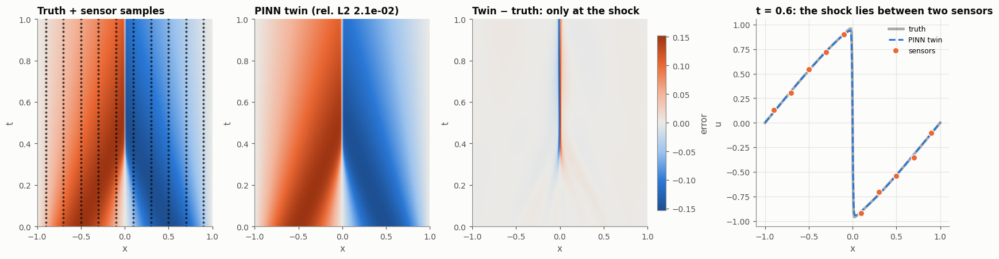

In [10]:
fig = plt.figure(figsize=(15, 4), constrained_layout=True)
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.1])
ax = fig.add_subplot(gs[0])
viz.spacetime(ax, U_exact, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, cbar=False)
ax.scatter(SX.ravel(), ST.ravel(), s=3, color=viz.INK, alpha=0.6)
ax.set_title("Truth + sensor samples")
ax = fig.add_subplot(gs[1])
viz.spacetime(ax, U_inv, xg, tg, cmap=viz.DIVERGING, vmin=-1, vmax=1, cbar=False)
ax.set_title(f"PINN twin (rel. L2 {rel_inv:.1e})")
ax = fig.add_subplot(gs[2])
e = U_inv - U_exact
viz.spacetime(ax, e, xg, tg, cmap=viz.DIVERGING, vmin=-np.abs(e).max(), vmax=np.abs(e).max(), label="error")
ax.set_title("Twin − truth: only at the shock")
ax = fig.add_subplot(gs[3])
k = np.argmin(abs(tg - 0.6))
ax.plot(xg, U_exact[k], color=viz.TRUTH, lw=3, alpha=0.35, label="truth")
ax.plot(xg, U_inv[k], "--", color=viz.TWIN, label="PINN twin")
j = np.argmin(abs(sens_t - 0.6))
ax.plot(sens_x, Y_noisy[j], "o", color=viz.DATA, mec="white", ms=7, label="sensors")
ax.set(xlabel="x", ylabel="u", title="t = 0.6: the shock lies between two sensors")
ax.legend(fontsize=8)
viz.save(fig, "08_pinn_inverse.png")
plt.show()

The **field** is reconstructed very well, but $\hat\nu$ is noticeably off. That's not a training
bug; it is **physics**. For small $\nu$, Burgers' equation is in the *inviscid limit*: the energy
dissipated at a shock is $\approx \Delta u^3/12$ per unit time, **independent of ν**. Viscosity only
sets the shock thickness ($\sim 2\nu/\Delta u \approx 0.003$), far below the 0.2 sensor spacing. Many
values of ν explain the data equally well: ν is **practically non-identifiable** from these sensors
(compare the flat valleys of Chapter 2).

**Check:** repeat in a smoother regime, $\nu^\star = 0.1/\pi$, where the front is ~0.06 wide and
visible to the sensors. Start from a guess 6× too *small* this time.

adam     0  loss 1.021e+01  pde 2.15e-01  data 3.80e-01  nu 5.00e-03  (0s)


adam  1000  loss 1.521e-02  pde 7.42e-03  data 4.55e-04  nu 3.33e-02  (23s)


adam  1999  loss 7.554e-03  pde 2.66e-03  data 4.04e-04  nu 3.26e-02  (45s)


lbfgs done  loss 3.894e-03  (70s)
smooth regime: nu = 0.0316 (true 0.0318, error 0.7%)  (70s)


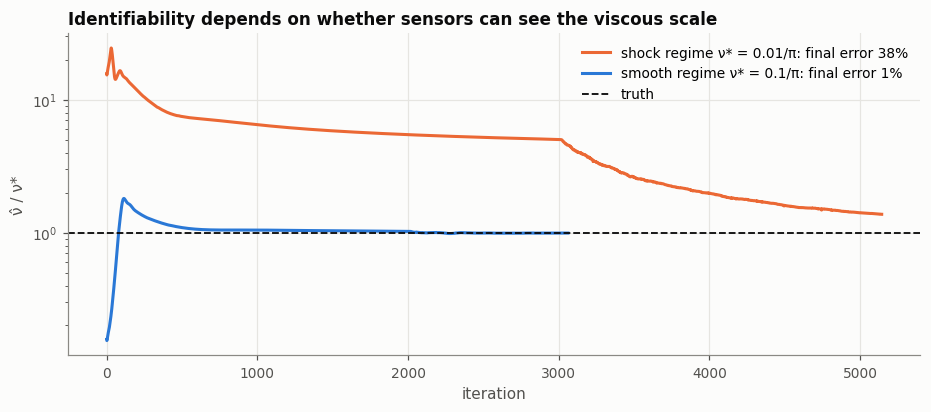

In [11]:
t0 = time.time()
smooth = run_inverse(0.1 / np.pi, 0.005, n_adam=2000, n_lbfgs=1000, seed=2)
print(f"smooth regime: nu = {smooth['nu_hat']:.4f} (true {0.1/np.pi:.4f}, "
      f"error {abs(smooth['nu_hat']/smooth['nu_true']-1)*100:.1f}%)  ({time.time()-t0:.0f}s)")

fig, ax = plt.subplots(figsize=(10, 3.8))
for case, col, name in [(shock, viz.ORANGE, "shock regime ν* = 0.01/π"),
                        (smooth, viz.BLUE, "smooth regime ν* = 0.1/π")]:
    ax.plot(np.array(case["nu"]) / case["nu_true"], color=col, label=f"{name}: final error "
            f"{abs(case['nu_hat']/case['nu_true']-1)*100:.0f}%")
ax.axhline(1, color=viz.TRUTH, ls="--", lw=1.2, label="truth")
ax.set(yscale="log", xlabel="iteration", ylabel="ν̂ / ν*",
       title="Identifiability depends on whether sensors can see the viscous scale")
ax.legend()
plt.show()

In [12]:
idx = np.arange(0, len(tg), 2)
jdx = [np.argmin(abs(sens_t - tt)) for tt in tg[idx]]
anim = viz.animate_1d(xg, [U_exact[idx], U_inv[idx]], tg[idx], labels=["truth", "PINN twin"],
                      colors=[viz.TRUTH, viz.TWIN], styles=["-", "--"], points=(sens_x, Y_noisy[jdx]),
                      title="Burgers twin", ylim=(-1.2, 1.2))
HTML(anim.to_jshtml())

## A5. Expert practice notes
| Issue | Symptom | Remedies |
|---|---|---|
| Loss imbalance | one term stalls while others drop | fixed weights (as here), adaptive weights (gradient-norm balancing, NTK, self-adaptive) |
| Spectral bias | sharp fronts learned last or never | Fourier features, residual-based adaptive sampling (RAR), more points near fronts |
| Causality violation | late times fitted before early ones | causal weighting / time-marching windows |
| Stiff optimisation | Adam plateaus | Adam → L-BFGS, learning-rate decay, float64 for the last phase |
| Unscaled inputs/outputs | slow or no training | normalise inputs to $[-1,1]$ (done in `MLP`), non-dimensionalise the PDE |

**PINN vs. Kalman filter as twin engines:** a PINN does smoothing over a whole time window
(past and future data at once) and needs no mesh. It handles nonlinear PDEs and parameters
naturally, but must be retrained or fine-tuned as new data arrive and has no built-in
uncertainty. Filters are sequential, cheap per step, and quantify uncertainty. Hybrids (PINN
surrogate + EnKF, or ensembles of PINNs) are an active research area.

**Exercises**
1. Remove the initial-condition loss in the inverse problem. Can the sensors alone pin down the solution?
2. Add 6 sensors clustered within ±0.02 of the shock. Does $\nu$ become identifiable in the shock regime?
3. Add residual-based adaptive refinement: every 500 iterations add 500 collocation points where $|\mathcal R|$ is largest.

---
# Part B · A PINN twin in 2D: reconstruct, identify, forecast

A puff of contaminant is released into a flowing channel, and a 6×6 array of probes records it.
Nothing else is known: not the release point, not the initial size, not the flow velocity, not
the diffusivity. The PINN twin must:

1. **reconstruct** the full space-time field $c(x,y,t)$ between the probes,
2. **identify** the physics: diffusivity $\kappa$ and velocity $(v_x, v_y)$,
3. **forecast** beyond the last measurement, where only the PDE constrains the network.

$$c_t + v_x c_x + v_y c_y = \kappa\,(c_{xx}+c_{yy})$$

Notice what is *missing* compared to Part A: no initial condition and no boundary conditions.
Sensors plus the PDE are enough, which makes PINNs attractive for twins whose initial state is
unknown.

In [13]:
set_seed(0)
rng = np.random.default_rng(0)

## B1. Reality: an advected, diffusing Gaussian puff (exact solution)

936 noisy readings from 36 probes


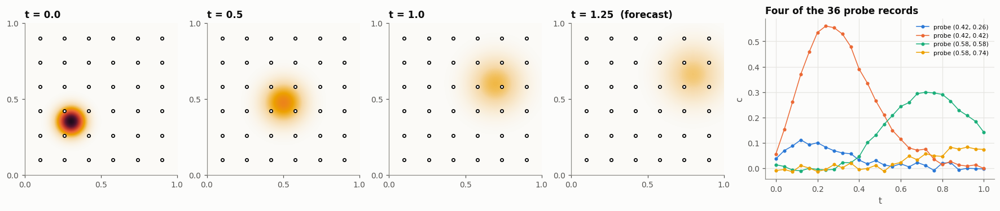

In [14]:
KAPPA, VX, VY = 0.005, 0.4, 0.25
X0, Y0, S0 = 0.3, 0.35, 0.06
T_DATA, T_FORECAST = 1.0, 1.3

def puff(x, y, t):
    s2 = S0**2 + 2 * KAPPA * t
    return S0**2 / s2 * np.exp(-((x - X0 - VX * t) ** 2 + (y - Y0 - VY * t) ** 2) / (2 * s2))

ng = 80
xg = np.linspace(0, 1, ng)
XX, YY = np.meshgrid(xg, xg)
tg = np.linspace(0, T_FORECAST, 40)
C_true = np.array([puff(XX, YY, t) for t in tg])

k_sens = 6
sp = np.linspace(0.1, 0.9, k_sens)
SXg, SYg = np.meshgrid(sp, sp)
sx, sy = SXg.ravel(), SYg.ravel()
st = np.linspace(0, T_DATA, 26)
Y_clean = np.array([puff(sx, sy, t) for t in st])          # (26, 36)
Y_noisy = Y_clean + 0.01 * rng.standard_normal(Y_clean.shape)
print(f"{Y_noisy.size} noisy readings from {sx.size} probes")

show_t = [0.0, 0.5, 1.0, 1.25]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.3), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.5]})
for ax, tt in zip(axes[:4], show_t):
    viz.field(ax, puff(XX, YY, tt), vmin=0, vmax=1, cbar=False,
              title=f"t = {tt}" + ("  (forecast)" if tt > T_DATA else ""))
    viz.sensors_2d(ax, sx, sy, s=12)
ax = axes[4]
for i, j in enumerate([8, 14, 21, 27]):
    ax.plot(st, Y_noisy[:, j], "o-", ms=3, lw=1, color=viz.SERIES[i], label=f"probe ({sx[j]:.2f}, {sy[j]:.2f})")
ax.set(xlabel="t", ylabel="c", title="Four of the 36 probe records")
ax.legend(fontsize=7)
plt.show()

## B2. The PINN twin
* Input $(x, y, t)$ → output $c$; 4 hidden layers × 48 tanh units, 6,000 collocation points.
* Unknowns: network weights + $\log\kappa$, $v_x$, $v_y$, initialised to κ = 0.02 and **no flow**.
* Collocation points cover $t\in[0, 1.3]$; data only cover $t\le1$. On $(1, 1.3]$ the PDE alone
  drives the solution, which is the forecast.
* Loss weights: data 20, PDE 1. Too much data weight lets the network fit the probes while ignoring
  the PDE, and then κ (which only the PDE term "sees") learns very slowly.

In [15]:
Xc = tensor(np.c_[rng.uniform(0, 1, 6000), rng.uniform(0, 1, 6000), rng.uniform(0, T_FORECAST, 6000)],
            requires_grad=True)
STT, SI = np.meshgrid(st, np.arange(sx.size), indexing="ij")
Xd = tensor(np.c_[sx[SI.ravel()], sy[SI.ravel()], STT.ravel()])
Yd = tensor(Y_noisy.ravel()[:, None])

net = MLP(3, 1, width=48, depth=4, lb=[0, 0, 0], ub=[1, 1, T_FORECAST])
log_k = torch.nn.Parameter(torch.tensor(np.log(0.02), dtype=torch.float32))
vx = torch.nn.Parameter(torch.tensor(0.0))
vy = torch.nn.Parameter(torch.tensor(0.0))

def pde_residual(X):
    c = net(X)
    d = grad(c, X)
    cx, cy, ct = d[:, :1], d[:, 1:2], d[:, 2:]
    cxx = grad(cx, X)[:, :1]
    cyy = grad(cy, X)[:, 1:2]
    return ct + vx * cx + vy * cy - torch.exp(log_k) * (cxx + cyy)

def loss_fn():
    lr = (pde_residual(Xc) ** 2).mean()
    ld = ((net(Xd) - Yd) ** 2).mean()
    return lr + 20 * ld, {"pde": lr.item(), "data": ld.item(), "kappa": torch.exp(log_k).item(),
                           "vx": vx.item(), "vy": vy.item()}

groups = [{"params": list(net.parameters())}, {"params": [log_k, vx, vy], "lr": 1e-2}]
t0 = time.time()
hist = train(loss_fn, groups, n_adam=4000, lr=2e-3, n_lbfgs=2000, log_every=1000)
print(f"trained in {time.time() - t0:.0f}s")

adam     0  loss 1.040e+00  pde 1.42e-01  data 4.49e-02  kappa 2.00e-02  vx 0.00e+00  vy 0.00e+00  (0s)


adam  1000  loss 4.088e-03  pde 5.34e-04  data 1.78e-04  kappa 1.47e-03  vx 4.04e-01  vy 2.15e-01  (23s)


adam  2000  loss 3.247e-03  pde 5.25e-04  data 1.36e-04  kappa 1.94e-03  vx 4.05e-01  vy 2.25e-01  (45s)


adam  3000  loss 2.873e-03  pde 4.68e-04  data 1.20e-04  kappa 2.16e-03  vx 4.06e-01  vy 2.32e-01  (68s)


adam  3999  loss 2.641e-03  pde 4.22e-04  data 1.11e-04  kappa 2.26e-03  vx 4.07e-01  vy 2.35e-01  (91s)


lbfgs done  loss 1.661e-03  (139s)
trained in 139s


kappa  estimated 0.0041   true 0.0050   error 17.9%
vx     estimated 0.4061   true 0.4000   error 1.5%
vy     estimated 0.2514   true 0.2500   error 0.6%


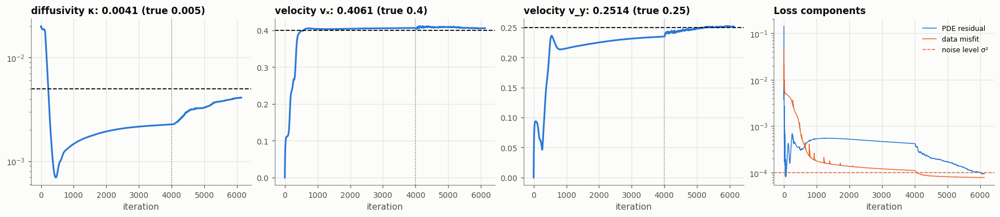

In [16]:
est = {"kappa": hist["kappa"][-1], "vx": hist["vx"][-1], "vy": hist["vy"][-1]}
truth = {"kappa": KAPPA, "vx": VX, "vy": VY}
for k in est:
    print(f"{k:6s} estimated {est[k]:.4f}   true {truth[k]:.4f}   error {abs(est[k]/truth[k]-1)*100:.1f}%")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), constrained_layout=True)
n_adam = hist["phase"].count("adam")
for ax, k, lbl in zip(axes[:3], ["kappa", "vx", "vy"], ["diffusivity κ", "velocity vₓ", "velocity v_y"]):
    ax.plot(hist[k], color=viz.TWIN)
    ax.axhline(truth[k], color=viz.TRUTH, ls="--", lw=1.2)
    ax.axvline(n_adam, color=viz.MUTED, ls=":", lw=1)
    ax.set(xlabel="iteration", title=f"{lbl}: {est[k]:.4f} (true {truth[k]})")
axes[0].set_yscale("log")
axes[3].semilogy(hist["pde"], color=viz.SERIES[0], lw=1, label="PDE residual")
axes[3].semilogy(hist["data"], color=viz.SERIES[1], lw=1, label="data misfit")
axes[3].axhline(0.01**2, color=viz.DATA, ls="--", lw=1, label="noise level σ²")
axes[3].set(xlabel="iteration", title="Loss components")
axes[3].legend(fontsize=8)
plt.show()

The data misfit settles near the **noise level** σ² = 10⁻⁴ (dashed): the twin fits the signal,
not the noise. Going lower would mean over-fitting.

**Why is κ the least accurate?** The velocities move the puff's *centre*, which 36 probes track
easily (first-order effect). κ only changes the puff's *width* (σ² grows from 0.0036 to 0.0136
over the record), a second-order effect sampled by probes 0.16 apart and partly confounded with
the unknown initial size. Expect ~10-20% on κ and ~1-2% on velocities: the same identifiability
lesson as Chapter 2 and Part A.

## B3. Physics vs. interpolation: reconstruction and forecast
Baseline: cubic interpolation of the 36 probes at each time (data only, no physics). It cannot
forecast at all, so we hold its last frame for $t>1$ (persistence).

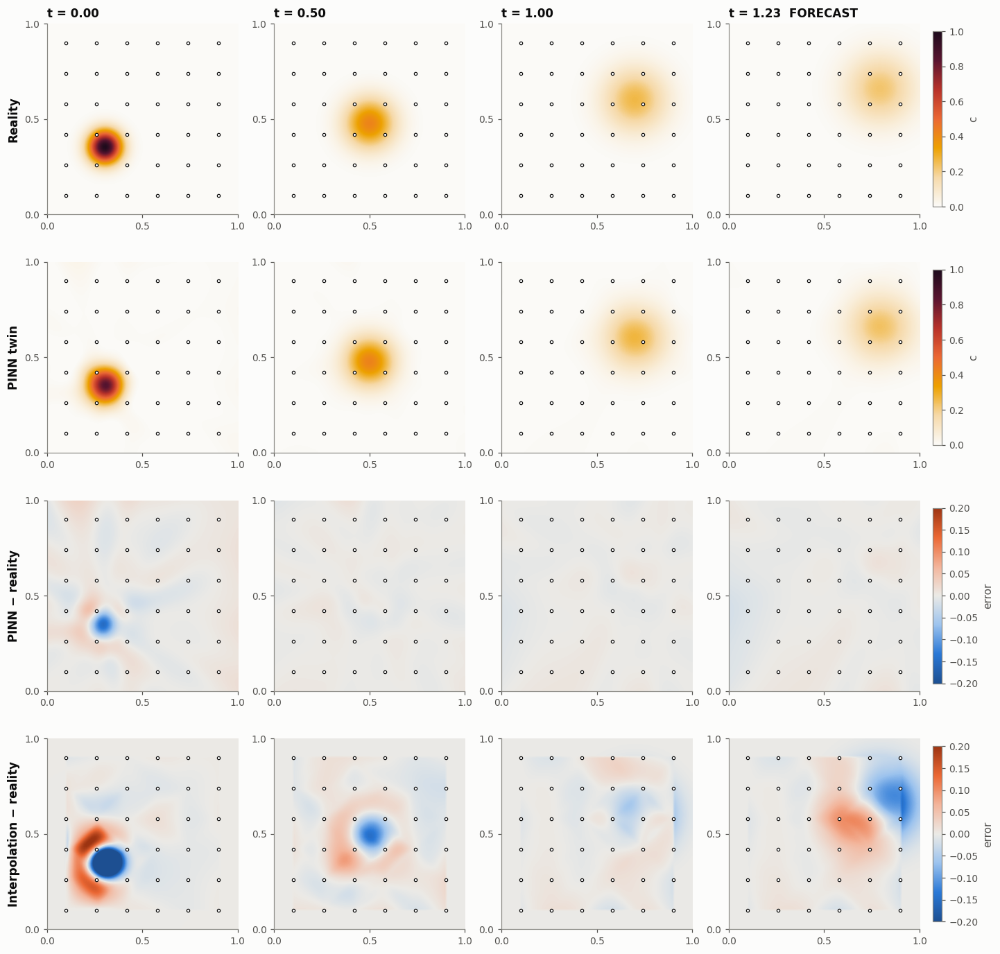

In [17]:
def pinn_field(t):
    pts = tensor(np.c_[XX.ravel(), YY.ravel(), np.full(XX.size, t)])
    with torch.no_grad():
        return net(pts).numpy().reshape(XX.shape)

def interp_field(t):
    j = np.argmin(abs(st - min(t, T_DATA)))
    return griddata((sx, sy), Y_noisy[j], (XX, YY), method="cubic", fill_value=0.0)

C_pinn = np.array([pinn_field(t) for t in tg])
C_intp = np.array([interp_field(t) for t in tg])

fig, axes = plt.subplots(4, 4, figsize=(13, 12.5), constrained_layout=True)
for j, tt in enumerate(show_t):
    k = np.argmin(abs(tg - tt))
    tag = f"t = {tg[k]:.2f}" + ("  FORECAST" if tg[k] > T_DATA else "")
    viz.field(axes[0, j], C_true[k], vmin=0, vmax=1, cbar=j == 3, label="c", title=tag)
    viz.field(axes[1, j], C_pinn[k], vmin=0, vmax=1, cbar=j == 3, label="c")
    viz.field(axes[2, j], C_pinn[k] - C_true[k], cmap=viz.DIVERGING, vmin=-0.2, vmax=0.2, cbar=j == 3, label="error")
    viz.field(axes[3, j], C_intp[k] - C_true[k], cmap=viz.DIVERGING, vmin=-0.2, vmax=0.2, cbar=j == 3, label="error")
    for r in range(4):
        viz.sensors_2d(axes[r, j], sx, sy, s=8, linewidth=0.8)
for r, name in enumerate(["Reality", "PINN twin", "PINN − reality", "Interpolation − reality"]):
    axes[r, 0].set_ylabel(name, fontsize=11, color=viz.INK, fontweight="semibold")
viz.save(fig, "09_pinn_2d.png")
plt.show()

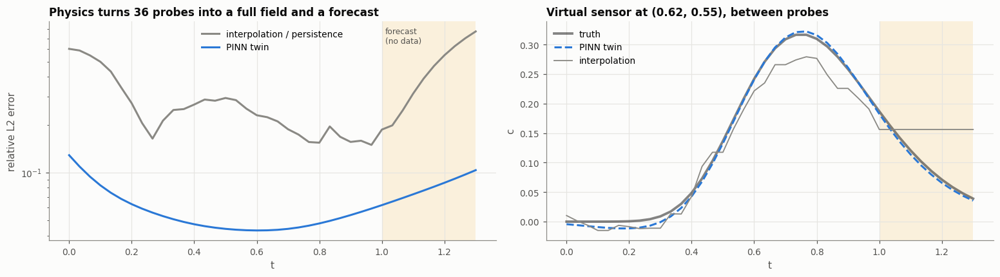

In [18]:
rel = lambda A: np.linalg.norm((A - C_true).reshape(len(tg), -1), axis=1) / np.linalg.norm(C_true.reshape(len(tg), -1), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
ax = axes[0]
ax.axvspan(T_DATA, T_FORECAST, color=viz.YELLOW, alpha=0.12, lw=0)
ax.text(T_DATA + 0.01, 0.9, "forecast\n(no data)", transform=ax.get_xaxis_transform(), fontsize=8, color=viz.INK2)
ax.semilogy(tg, rel(C_intp), color=viz.MUTED, label="interpolation / persistence")
ax.semilogy(tg, rel(C_pinn), color=viz.TWIN, label="PINN twin")
ax.set(xlabel="t", ylabel="relative L2 error", title="Physics turns 36 probes into a full field and a forecast")
ax.legend()
ax = axes[1]
vp = (0.62, 0.55)                                  # a virtual sensor between probes
iv = (np.argmin(abs(xg - vp[1])), np.argmin(abs(xg - vp[0])))
ax.axvspan(T_DATA, T_FORECAST, color=viz.YELLOW, alpha=0.12, lw=0)
ax.plot(tg, C_true[:, iv[0], iv[1]], color=viz.TRUTH, lw=2.5, alpha=0.5, label="truth")
ax.plot(tg, C_pinn[:, iv[0], iv[1]], "--", color=viz.TWIN, label="PINN twin")
ax.plot(tg, C_intp[:, iv[0], iv[1]], color=viz.MUTED, lw=1.2, label="interpolation")
ax.set(xlabel="t", ylabel="c", title=f"Virtual sensor at ({vp[0]}, {vp[1]}), between probes")
ax.legend()
plt.show()

In [19]:
anim = viz.animate_2d([C_true, C_pinn, C_pinn - C_true], tg, ["Reality", "PINN twin", "Twin − reality"],
                      cmaps=[viz.FIELD, viz.FIELD, viz.DIVERGING], vlims=[(0, 1), (0, 1), (-0.15, 0.15)],
                      sensors=(sx, sy), size=3.3, interval=150)
HTML(anim.to_jshtml())

## B4. Where did the puff come from? Back-tracking the source
The twin's field at $t=0$ is an estimate of the **release**, even though no probe was near it.
This works because advection-diffusion is (mildly) invertible backwards for short times. It
would degrade quickly for longer horizons, since diffusion destroys information.

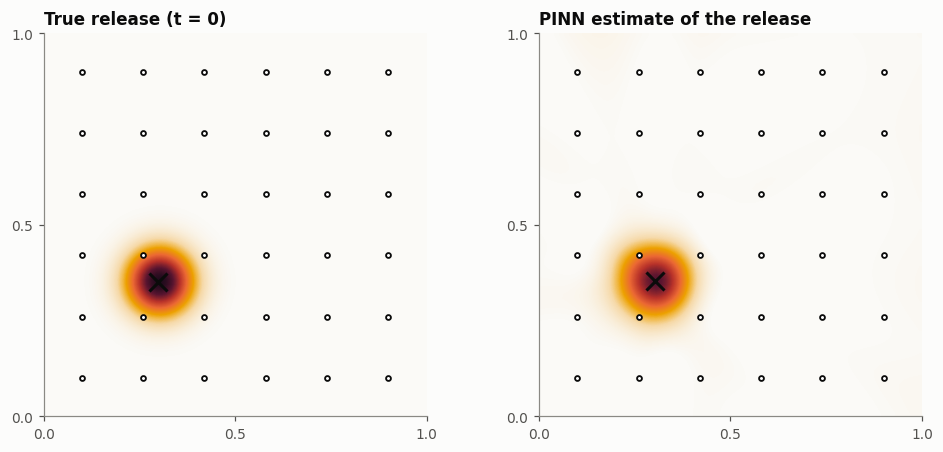

estimated release point (0.304, 0.354), true (0.3, 0.35)


In [20]:
c0_hat = C_pinn[0]
iy, ix = np.unravel_index(np.argmax(c0_hat), c0_hat.shape)
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
viz.field(axes[0], C_true[0], vmin=0, vmax=1, cbar=False, title="True release (t = 0)")
viz.field(axes[1], c0_hat, vmin=0, vmax=1, cbar=False, title="PINN estimate of the release")
for ax in axes:
    viz.sensors_2d(ax, sx, sy, s=10)
axes[1].plot(xg[ix], xg[iy], "x", color=viz.INK, ms=12, mew=2)
axes[0].plot(X0, Y0, "x", color=viz.INK, ms=12, mew=2)
plt.show()
print(f"estimated release point ({xg[ix]:.3f}, {xg[iy]:.3f}), true ({X0}, {Y0})")

## Part B remarks
* One loss function performs **state reconstruction, parameter identification and forecasting**.
* No initial or boundary conditions were needed: data + PDE regularise each other.
* Fit to the noise level, not below it. Use the noise floor to choose loss weights.
* **Limits:** training takes minutes (not milliseconds); there are no native error bars (use deep
  ensembles or Bayesian PINNs); long forecasts drift once data stop constraining the network; and
  strongly multiscale or turbulent fields remain hard.
* In operational twins, PINNs often serve as **offline calibrators or surrogates**, while fast filters
  (Chapters 3–4) do the real-time tracking. The capstone (Chapter 6) combines exactly these pieces.

**Exercises**
1. Use 3×3 probes. Which parameter degrades first?
2. Extend the forecast window to $t=2$. Where does the error grow, and why?
3. Train 5 PINNs with different seeds (a deep ensemble) and map the standard deviation of the field.

---
# Chapter recap
* A PINN = a network for the field + autograd for derivatives + a loss that mixes physics and data.
* Unknown constants become trainable numbers, so reconstruction and calibration happen in one training run.
* PINNs need **no grid and no initial condition**, but they are slow to train and sensitive to
  loss weights.
* **Identifiability still rules.** Near a shock, very different viscosities fit the data almost
  equally well, and κ is the hardest parameter in 2D. No optimiser can recover what the data
  don't contain.

## When to choose a PINN, and when not to
| Use a PINN when… | Prefer a classic solver + EnKF when… |
|---|---|
| the initial or boundary conditions are unknown | they are known |
| data are scattered in space and time | data stream in regularly |
| you need a smooth, differentiable field | you need speed and robustness |
| it's an offline analysis | it's a live, real-time twin |

## Quick quiz
1. Why does the 1D PINN need L-BFGS after Adam?
2. The PDE loss is tiny but the field is wrong. Name two possible causes.

<details><summary>Answers</summary>

1. Adam gets close but jitters; L-BFGS uses curvature information to converge much more precisely
   near the minimum.
2. Too few collocation points where the action happens (the shock), or a data or initial-condition
   weight that is too small, so the network found a different solution of the same PDE.
</details>